# Scoring Validation

Goal: show that the scoring formula behaves as intended and **justify its parameters** with measurements.

$$S(b) = P\left(\frac{\sum_k w_k\, z_k(b)}{\sum_k w_k}\right) - \text{penalty}(b) \qquad z_k(b) = \frac{x_k(b) - \overline{x_k}}{\sigma_k} \qquad k \in \{\text{text}, \text{categories}, \text{references}\}$$

1. How the signals are combined: percentiles vs z-scores
2. Typical user profiles: Top 5 and explanations
3. Contribution of each signal (ablation)
4. Sensitivity: Likert / semantic mix, weights of the signals
5. Sensitivity of the "avoid" penalty
6. Conclusions

**Proxy ground truth.** There is no record of real user satisfaction, so the thematic categories are used as a proxy — only those coming from the books' own Freebase genres (a category *inferred* by TF-IDF for a book with vague genres never counts as a correct answer). A second, finer set of 16 readers targets precise Freebase **sub-genres** (dystopia, spy fiction…). Two metrics are always reported together:
- `category_p10`: share of the top 10 books in the category the user is looking for;
- `text_fidelity`: mean percentile of the **text** similarity of the top 10 — does the top still respect what the user wrote?

Optimizing `category_p10` alone would push towards trusting the declared ratings only; `text_fidelity` guards the semantic part.

In [1]:
# Make the project root importable (notebooks live in notebooks/)
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

## Imports and engine

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data.data import load_config, load_books
from src.data.categories import load_categories
from src.nlp import scoring
from src.nlp.scoring import Scorer, UserProfile
from src.nlp.similarity import cosine
from src.recommendation.engine import recommend
from src.nlp import validation as V

config = load_config(ROOT / "configs/data.yaml")
df, vectors = load_books(root=ROOT)
categories = list(load_categories(ROOT / "configs/categories.yaml")["categories"])
cat_config = load_categories(ROOT / "configs/categories.yaml")
scorer = Scorer(df, vectors["book"], categories, config["embeddings"]["model"])   # summary + genres (notebook 02)
print(df.shape, "| model:", config["embeddings"]["model"])
print("Parameters:", {"likert_weight": scorer.likert_weight, "avoid_lambda": scorer.avoid_lambda,
                      "avoid_threshold": scorer.avoid_threshold, "default_weights": scoring.DEFAULT_WEIGHTS,
                      "combine": scorer.combine, "genre_weight": config["embeddings"]["genre_weight"]})

(12040, 9) | model: all-mpnet-base-v2
Parameters: {'likert_weight': 0.5, 'avoid_lambda': 0.3, 'avoid_threshold': 0.9, 'default_weights': {'text': 0.5, 'categories': 0.3, 'references': 0.2}, 'combine': 'zscore', 'genre_weight': 0.5}


## 1. How the signals are combined

The three signals are raw cosine similarities (or a weighted mean of them) with **different, compressed ranges**: summing them directly would let the signal with the widest spread dominate, whatever the weights.

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

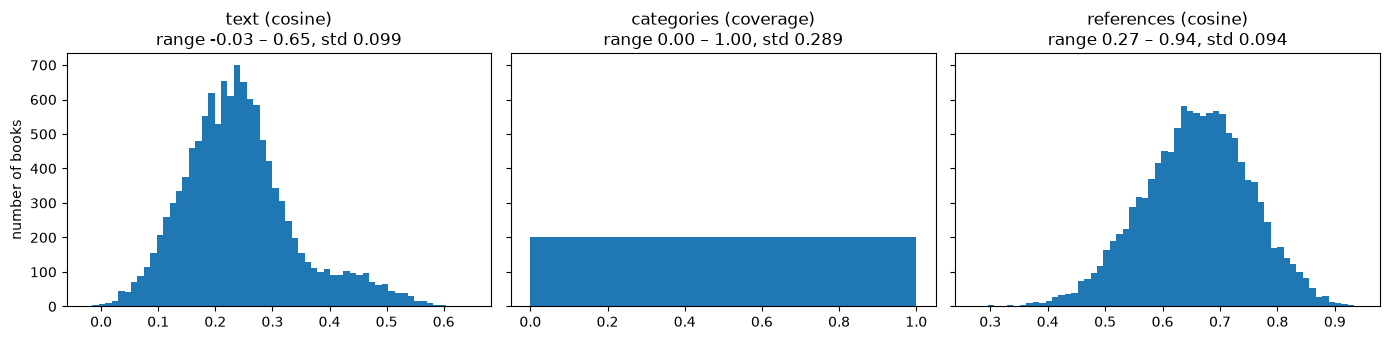

In [3]:
user = UserProfile(texts=["A detective investigates a murder in a small village"],
                   likert={"Mystery & Crime": 5}, authors=["Agatha Christie"])
result = scorer.score(user)
raw = {"text (cosine)": result.ranking["cos_text"], "categories (coverage)": result.ranking["coverage"],
       "references (cosine)": result.ranking["cos_references"]}

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, (name, values) in zip(axes, raw.items()):
    ax.hist(values, bins=60)
    ax.set_title(f"{name}\nrange {values.min():.2f} – {values.max():.2f}, std {values.std():.3f}")
axes[0].set_ylabel("number of books")
plt.tight_layout()

**First version: percentiles.** Each signal was converted into a percentile over the corpus before being combined. Same scale, easy to read — but a percentile **squashes the top**: every serious candidate is at 0.99-something on its best signal, so a book that is *far* ahead on the text (a real dystopia for a dystopia request) gains nothing over a book that is merely good on all three, and generic books win.

**Adopted: z-scores.** Each signal is standardized over the corpus ($z$ = how many standard deviations above the average book), the weighted mean of the z-scores keeps the size of each lead, and only the **final** value is turned into a percentile (score out of 100). Comparison on both sets of simulated readers, with the old (summary only) and the new (summary + genres) book vectors:

In [4]:
query_personas = V.query_personas(df, seed=0)
subgenre_personas = V.subgenre_personas(df, cat_config, seed=0)
rows = []
for vec_name, key in [("summary only", "synopsis"), ("summary + genres", "book")]:
    s = Scorer(df, vectors[key], categories, config["embeddings"]["model"])
    for set_name, P in [("33 category readers", query_personas), ("16 sub-genre readers", subgenre_personas)]:
        for _, r in V.combination_comparison(s, P).iterrows():
            rows.append({"book vector": vec_name, "readers": set_name, "combination": r["combination"],
                         "p10": r["category_p10"], "text_fidelity": r["text_fidelity"]})
comb = pd.DataFrame(rows)
comb.pivot_table(index=["readers", "book vector"], columns="combination", values="p10").round(3)

combination                            percentile  zscore
readers              book vector                         
16 sub-genre readers summary + genres       0.256   0.588
                     summary only           0.131   0.238
33 category readers  summary + genres       0.733   0.888
                     summary only           0.485   0.542

## 2. Typical user profiles

Hand-written profiles combining every type of answer. For each: the Top 5 and the template explanation of the first book.

In [5]:
personas = {
    "Science-fiction reader": UserProfile(
        texts=["A story about artificial intelligence, robots and what makes us human",
               "I am looking for a book with a fast-paced, action-packed plot; set in the future."],
        text_weights=[1, 0.5], likert={"Science Fiction": 5, "Romance": 1}, authors=["Isaac Asimov"],
        avoid="romance, love story"),
    "Cozy mystery fan": UserProfile(
        texts=["A clever amateur sleuth solving a murder in a quiet English village"],
        likert={"Mystery & Crime": 5, "Horror & Gothic": 1}, authors=["Agatha Christie"],
        avoid="graphic violence, gore", audience="adult"),
    "Literary fiction lover": UserProfile(
        texts=["A melancholic novel about memory, regret and a life that could have been different"],
        likert={"Literary Fiction": 5}, authors=["Kazuo Ishiguro"]),
    "Historical romance": UserProfile(
        texts=["A love story set in 19th-century England between people of different social classes"],
        likert={"Romance": 5, "Historical": 5}, authors=["Jane Austen"]),
    "Curious non-fiction reader": UserProfile(
        texts=["A book explaining science and the history of our world with humour"],
        likert={"Non-fiction": 5}, authors=["Bill Bryson"]),
    "Young fantasy reader": UserProfile(
        texts=["A young wizard discovers a magical world and goes to a school of magic"],
        likert={"Fantasy": 5}, authors=["Diana Wynne Jones"], audience="youth"),
}

for name, user in personas.items():
    result = scorer.score(user)
    recs = recommend(scorer, result, top_k=5)
    print("=" * 100)
    print(f"{name}  | weights {({k: round(w, 2) for k, w in result.weights.items()})} | authors {result.matched_authors}")
    display(pd.DataFrame([{"rank": r["rank"], "title": r["title"], "author": r["author"],
                           "categories": ", ".join(r["categories"]), "score /100": r["score_100"]} for r in recs]))
    print("Why #1:")
    for sentence in recs[0]["explanation"]:
        print("  -", sentence.replace("**", "").replace("*", ""))

Science-fiction reader  | weights {'text': 0.5, 'categories': 0.3, 'references': 0.2} | authors ['Isaac Asimov']


,rank,title,author,categories,score /100
0,1,Weapon,Robert Mason,Science Fiction,100.00
1,2,The Hacker and the Ants,Rudy Rucker,Science Fiction,99.99
2,3,Isaac Asimov's Robot City: Odyssey,Isaac Asimov,Science Fiction,99.98
3,4,The Modular Man,Roger MacBride Allen,Science Fiction,99.98
4,5,Isaac Asimov's Caliban,Roger MacBride Allen,Science Fiction,99.97


Why #1:
  - Its story is extremely close to what you asked for (top 0.1% of the books), especially your answer: “A story about artificial intelligence, robots and what makes us human”.
  - It is listed as Science Fiction, a kind of book you rated 5/5 (it is in the top 7% of the books closest to this category).
  - It is very close to the books of Isaac Asimov, which you love (top 3% of the books).


Cozy mystery fan  | weights {'text': 0.5, 'categories': 0.3, 'references': 0.2} | authors ['Agatha Christie']


,rank,title,author,categories,score /100
0,1,The Hanging Valley,Peter Robinson,Mystery & Crime,100.00
1,2,Aftermath,Peter Robinson,Mystery & Crime,99.99
2,3,A Dedicated Man,Peter Robinson,Mystery & Crime,99.98
3,4,Busman's Honeymoon,Dorothy L. Sayers,Mystery & Crime,99.98
4,5,Innocent Graves,Peter Robinson,Mystery & Crime,99.97


Why #1:
  - Its story is extremely close to what you asked for (top 0.1% of the books), especially your answer: “A clever amateur sleuth solving a murder in a quiet English village”.
  - It is listed as Mystery & Crime, a kind of book you rated 5/5 (it is in the top 0.1% of the books closest to this category).
  - It is extremely close to the books of Agatha Christie, which you love (top 0.5% of the books).


... (8 outputs left out)

Why #1:
  - Its story is extremely close to what you asked for (top 0.1% of the books), especially your answer: “A book explaining science and the history of our world with humour”.
  - Its content is typical of Non-fiction, a kind of book you rated 5/5 (it is in the top 22% of the books closest to this category).
  - It is close to the books of Bill Bryson, which you love (top 11% of the books).


Young fantasy reader  | weights {'text': 0.5, 'categories': 0.3, 'references': 0.2} | authors ['Diana Wynne Jones']


,rank,title,author,categories,score /100
0,1,The Wizard in the Woods,Jean Ure,Fantasy,100.00
1,2,Witch Week,Diana Wynne Jones,Fantasy,99.99
2,3,Majo no Takkyūbin,Eiko Kadono,Fantasy,99.98
3,4,The Lives of Christopher Chant,Diana Wynne Jones,Fantasy,99.96
4,5,House of Many Ways,Diana Wynne Jones,Fantasy,99.95


Why #1:
  - Its story is extremely close to what you asked for (top 0.1% of the books), especially your answer: “A young wizard discovers a magical world and goes to a school of magic”.
  - It is close to the books of Diana Wynne Jones, which you love (top 10% of the books).
  - It is listed as Fantasy, a kind of book you rated 5/5 (it is in the top 41% of the books closest to this category).


## 3. Contribution of each signal (ablation)

33 personas built from the benchmark queries (3 per category): the query as free text, the target category rated 5/5 (others 3 = neutral) and **one** loved book drawn at random from the target category. Same test on the 16 sub-genre personas (precision = share of the top 10 carrying the target Freebase genre).

In [6]:
abl = pd.concat([V.ablation(scorer, query_personas).assign(readers="33 category"),
                 V.ablation(scorer, subgenre_personas).assign(readers="16 sub-genre")])
abl.round(3)

,signals,category_p10,text_fidelity,readers
0,story only,0.873,1.000,33 category
1,categories only,0.736,NaN,33 category
2,references only,0.645,NaN,33 category
3,all (default weights),0.888,0.999,33 category
0,story only,0.488,1.000,16 sub-genre
1,categories only,0.006,NaN,16 sub-genre
2,references only,0.575,NaN,16 sub-genre
3,all (default weights),0.588,0.998,16 sub-genre


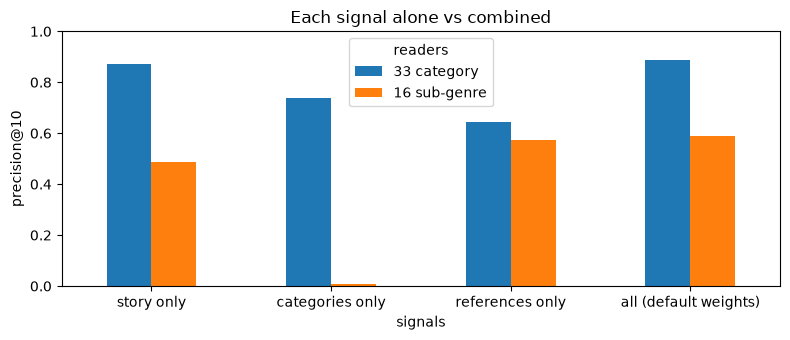

In [7]:
ax = abl.pivot_table(index="signals", columns="readers", values="category_p10", sort=False).plot.bar(figsize=(8, 3.5), rot=0)
ax.set_ylim(0, 1); ax.set_ylabel("precision@10"); ax.set_title("Each signal alone vs combined"); plt.tight_layout()

*Reading:* "story only" maximizes `text_fidelity` by construction; the combination should keep it high **and** improve the category match.

### 3.1 Why the coverage is centered

A first version weighted every block by the raw affinity: $\text{coverage}(b) = \sum_c a_c\, p_c(b) / \sum_c a_c$. With one category rated 5 and the others neutral (3), the 10 neutral blocks still received ≈ 0.25–0.3 each, so the requested block weighed only ≈ 24% of the coverage: "generalist" books, moderately close to every category, won.

Centered version (adopted): $\hat w_c = \max(0,\ a_c - \bar a)$ — only the blocks the user likes **more than their average** count. Comparison of the two:

In [8]:
def coverage_precision(centered: bool) -> dict:
    """Category precision@10 of the coverage alone, with raw or centered block weights."""
    p10_cat = []
    for target, user in query_personas:   # category readers only
        res = scorer.score(user)
        a = np.nan_to_num(res.category_affinity["affinity"].to_numpy())
        w = np.maximum(0, a - a.mean()) if centered else a
        cov = scorer.cat_profile @ w / w.sum()
        p10_cat.append(V.in_category(df.iloc[np.argsort(-cov)[:10]], target).mean())
    return {"coverage weighting": "centered (adopted)" if centered else "raw a_c (first version)",
            "categories-only p10": np.mean(p10_cat)}

pd.DataFrame([coverage_precision(False), coverage_precision(True)]).round(3)

,coverage weighting,categories-only p10
0,raw a_c (first version),0.064
1,centered (adopted),0.736


## 4. Sensitivity of the parameters

### 4.1 Likert / semantic mix in the category affinity

$a_c = \alpha \cdot \text{Likert}_c + (1-\alpha) \cdot \text{semantic}_c$ — current value α = 0.5.

,likert_weight,category_p10,text_fidelity
0,0.00,0.855,0.999
1,0.25,0.888,0.999
2,0.50,0.888,0.999
3,0.75,0.888,0.999
4,1.00,0.888,0.999


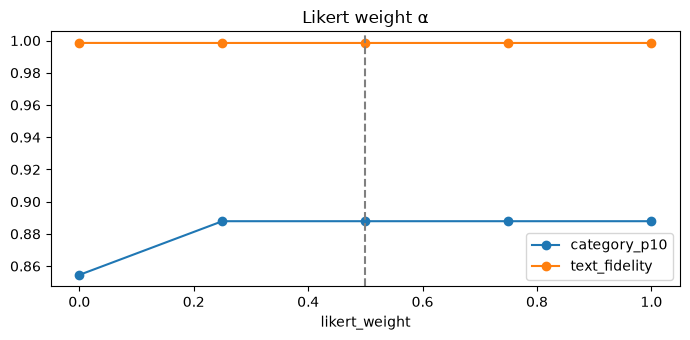

In [9]:
lik = V.likert_sensitivity(scorer, query_personas)
display(lik.round(3))
ax = lik.set_index("likert_weight")[["category_p10", "text_fidelity"]].plot(marker="o", figsize=(7, 3.5))
ax.axvline(scorer.likert_weight, ls="--", c="grey"); ax.set_title("Likert weight α"); plt.tight_layout()

### 4.2 Weights of the signals

,weights,category_p10,text_fidelity,readers
0,default (0.5 / 0.3 / 0.2),0.888,0.999,33 category
1,text dominant (0.7 / 0.2 / 0.1),0.903,0.999,33 category
2,balanced (1/3 each),0.809,0.990,33 category
3,categories dominant (0.2 / 0.6 / 0.2),0.782,0.986,33 category
4,references dominant (0.2 / 0.2 / 0.6),0.721,0.897,33 category
0,default (0.5 / 0.3 / 0.2),0.588,0.998,16 sub-genre
1,text dominant (0.7 / 0.2 / 0.1),0.525,0.999,16 sub-genre
2,balanced (1/3 each),0.669,0.982,16 sub-genre
3,categories dominant (0.2 / 0.6 / 0.2),0.444,0.977,16 sub-genre
4,references dominant (0.2 / 0.2 / 0.6),0.694,0.960,16 sub-genre


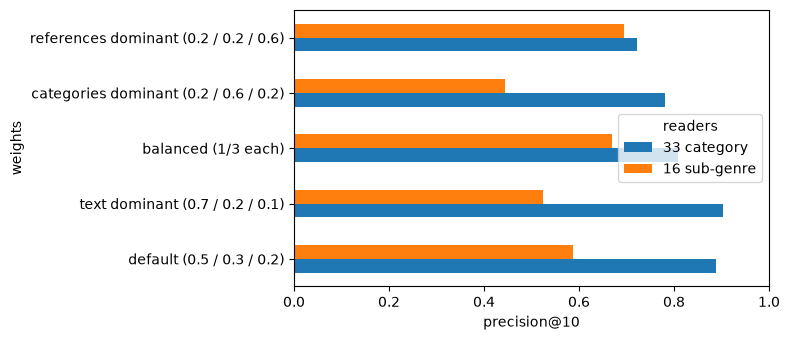

In [10]:
ws = pd.concat([V.weight_sensitivity(scorer, query_personas).assign(readers="33 category"),
                V.weight_sensitivity(scorer, subgenre_personas).assign(readers="16 sub-genre")])
display(ws.round(3))
ax = ws.pivot_table(index="weights", columns="readers", values="category_p10", sort=False).plot.barh(figsize=(8, 3.5))
ax.set_xlim(0, 1); ax.set_xlabel("precision@10"); plt.tight_layout()

## 5. Sensitivity of the "avoid" penalty

penalty = λ · max(0, (p_avoid − τ) / (1 − τ)) — values λ = 0.3, τ = 0.9 (τ was 0.8 before this analysis).

For 4 topics to avoid (romance, horror, magic, crime) and every query of the other categories:
- `avoided_share`: share of the avoided category in the top 20 (**lower** = the penalty works);
- `top_k_overlap`: overlap of the top 20 with the ranking without penalty (**higher** = fewer side effects).

In [11]:
pen = V.penalty_sensitivity(scorer)
pen.round(3)

,lambda,tau,avoided_share,top_k_overlap
0,0.0,NaN,0.018,1.000
1,0.1,0.7,0.006,0.699
2,0.1,0.8,0.007,0.811
3,0.1,0.9,0.010,0.917
4,0.3,0.7,0.006,0.695
5,0.3,0.8,0.007,0.806
6,0.3,0.9,0.010,0.916
7,0.5,0.7,0.007,0.693
8,0.5,0.8,0.007,0.805
9,0.5,0.9,0.010,0.915


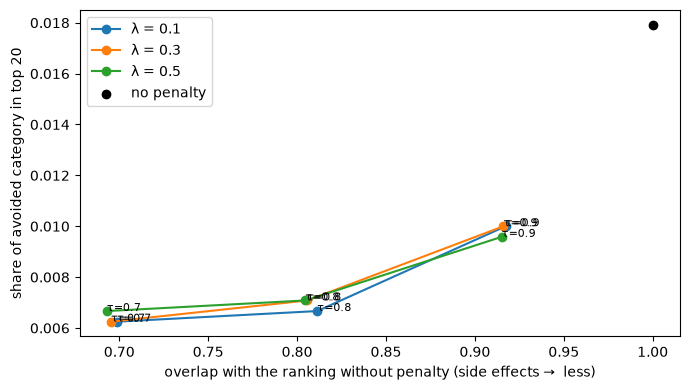

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
for lam, g in pen.dropna().groupby("lambda"):
    ax.plot(g["top_k_overlap"], g["avoided_share"], marker="o", label=f"λ = {lam}")
    for _, r in g.iterrows():
        ax.annotate(f"τ={r['tau']}", (r["top_k_overlap"], r["avoided_share"]), fontsize=8)
base = pen.iloc[0]
ax.scatter([base["top_k_overlap"]], [base["avoided_share"]], c="black", label="no penalty")
ax.set_xlabel("overlap with the ranking without penalty (side effects →  less)")
ax.set_ylabel("share of avoided category in top 20")
ax.legend(); plt.tight_layout()

## 6. Conclusions

Ground truth = the books' own Freebase genres; 33 simulated readers targeting a category, 16 targeting a precise sub-genre. Book vectors = summary + genres (notebook 02).

- **z-scores instead of percentiles:** combining percentiles squashed the top of the ranking. With z-scores, precision@10 rises from 0.733 to **0.888** (category readers) and from 0.256 to **0.588** (sub-genre readers); text fidelity stays ≥ 0.998. The gain exists with both book vectors, and the two fixes add up: from the first version (summary only, percentiles) to the final one, 0.485 → 0.888 and 0.131 → 0.588.
- **Ablation:** the full score now beats every signal alone — 0.888 vs 0.873 for the text alone (category readers), 0.588 vs 0.488 (sub-genre readers). The ratings and references now *add* information instead of diluting the text (with percentiles, the text alone was better: 0.521 vs 0.485). The category signal alone is useless for sub-genres (0.006): a category such as Science Fiction is far broader than "dystopia" — this is the role of the text.
- **Centered coverage:** raw affinities as weights found the requested category in 6.4% of the top 10 (category signal alone); centering raises it to **73.6%** — kept.
- **Likert share α:** flat from 0.25 to 1 (0.888), slightly lower at 0 (0.855): **α = 0.5 kept**.
- **Weights:** no setting wins on both reader sets — "text dominant" is best for categories (0.903) but worse for sub-genres (0.525), "balanced" the reverse (0.809 / 0.669). **Default 0.5 / 0.3 / 0.2 kept** as the compromise (0.888 / 0.588); the user can change them in the app.
- **Penalty:** the new engine already shows few books of an avoided category (1.8% of the top 20 without penalty). With **λ = 0.3, τ = 0.9 (kept)** this drops to 1.0% while 92% of the top 20 is unchanged; τ = 0.8 or 0.7 removes slightly more but changes 19–31% of the top. λ still barely matters.